# What does a Eurovision winner look like?

Every song in a grand final compared with the songs that won.
**Grey = all finalists, blue = winners.**

Every chart uses as many years as its data allows:

| chart | years | missing |
|---|---|---|
| age, gender | 1956–2026 | bands and duos have no age or gender, and some solo artists have no exact birth date in Wikidata |
| running order, countries | 1956–2026 | nothing |
| language, lyrics | 2008–2026 | 2010 (no lyrics data, so the 2010 winner Lena is missing) |
| Google searches | 2008–2026 | 2010 (no data); 2008 and 2009 almost empty, Google had too little search volume then |

Keep the numbers in mind: there are 72 winners since 1956 (1969 had four), but only 17 or 18 in the charts that start in 2008. A difference of a few winners is not a pattern.

In [26]:
%pip install -q pandas pyarrow matplotlib

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path("..")
PROCESSED = BASE / "data" / "processed"
INTERIM = BASE / "data" / "interim"

entries = pd.read_parquet(PROCESSED / "entries.parquet")
# 2020 was cancelled, the source still lists the Dutch host entry as a finalist
finals = entries[(entries["round"] == "final") & (entries["year"] != 2020)].copy()
finals["winner"] = finals["place"] == 1

# position in the running order from 0 (first) to 1 (last)
size = finals.groupby("year")["running_order"].transform("max")
finals["order_share"] = (finals["running_order"] - 1) / (size - 1)

names = pd.read_csv(BASE / "data" / "manual" / "country_names.csv", comment="#")
name = dict(zip(names["iso3"], names["name"]))

winners = finals[finals["winner"]]
print(len(finals), "songs in finals,", len(winners), "winners,",
      finals["year"].min(), "to", finals["year"].max())

1473 songs in finals, 72 winners, 1956 to 2026


In [28]:
ALL, WIN = "#b5b3ad", "#2a78d6"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e2dc", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "font.size": 11, "legend.frameon": False,
    "figure.dpi": 110,
})


def compare(ax, shares_all, shares_win, n_all, n_win, labels=None):
    """grey bars for all finalists, blue for winners, as % of each group"""
    x = np.arange(len(shares_all))
    width = 0.38
    ax.bar(x - (width + 0.02) / 2, shares_all * 100, width, color=ALL, label=f"All finalists (n={n_all})")
    bars = ax.bar(x + (width + 0.02) / 2, shares_win * 100, width, color=WIN, label=f"Winners (n={n_win})")
    ax.bar_label(bars, fmt="%.0f%%", padding=3, color=INK2, fontsize=9)
    ax.set_xticks(x, labels if labels is not None else shares_all.index)
    ax.set_ylabel("Share of songs (%)")
    ax.grid(axis="x", visible=False)
    ax.legend(loc="upper right")


def shares(series, order):
    return series.value_counts(normalize=True).reindex(order, fill_value=0)

## 1. Age at the final
Solo artists only, 1956–2026. Bands and duos have no age, and solo artists whose birth date Wikidata knows only to the year are left out too. That leaves 50 of the 72 winners.

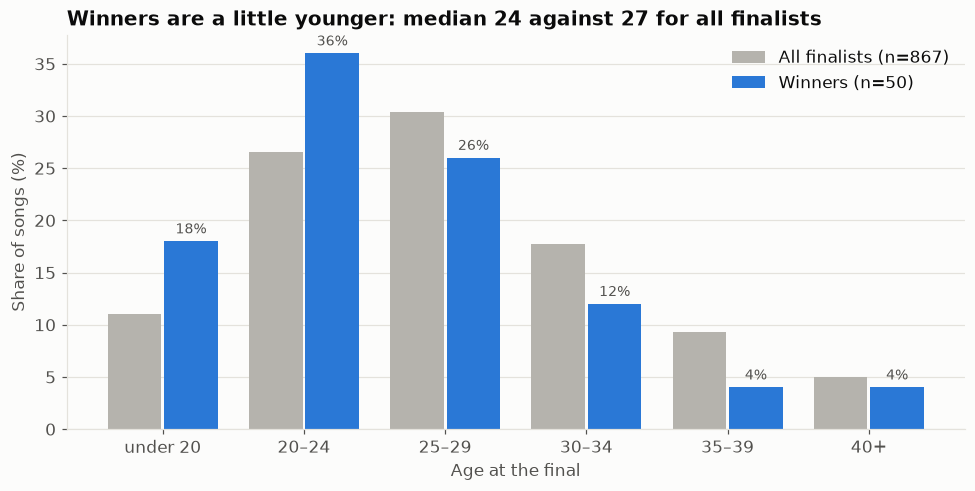

In [29]:
bins = [0, 20, 25, 30, 35, 40, 100]
labels = ["under 20", "20–24", "25–29", "30–34", "35–39", "40+"]
aged = finals.dropna(subset=["artist_age"]).copy()
aged["age_band"] = pd.cut(aged["artist_age"], bins=bins, labels=labels, right=False)
aged_win = aged[aged["winner"]]

fig, ax = plt.subplots(figsize=(9, 4.6))
compare(ax, shares(aged["age_band"], labels), shares(aged_win["age_band"], labels),
        len(aged), len(aged_win))
ax.set_xlabel("Age at the final")
ax.set_title(f"Winners are a little younger: median {aged_win['artist_age'].median():.0f} "
             f"against {aged['artist_age'].median():.0f} for all finalists")
plt.tight_layout(); plt.show()

## 2. Winners' age over time
Every dot is one winner. The grey line is the median age of all solo finalists that year.

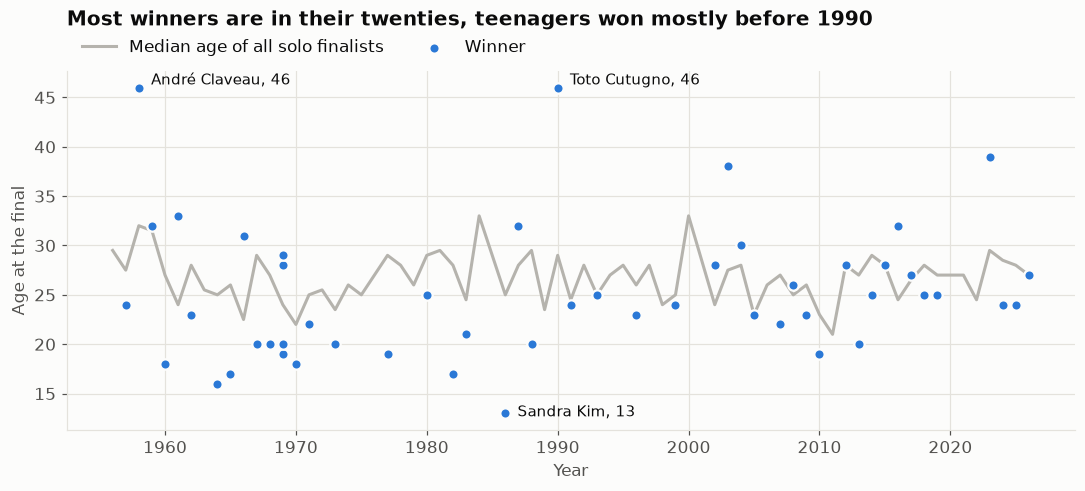

In [30]:
median_by_year = aged.groupby("year")["artist_age"].median()

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(median_by_year.index, median_by_year.values, color=ALL, linewidth=2,
        label="Median age of all solo finalists")
ax.scatter(aged_win["year"], aged_win["artist_age"], s=46, color=WIN,
           edgecolor=SURFACE, linewidth=1.5, zorder=3, label="Winner")
for _, row in aged_win.nsmallest(1, "artist_age").iterrows():
    ax.annotate(f"{row['artist']}, {row['artist_age']}", (row["year"], row["artist_age"]),
                xytext=(8, -2), textcoords="offset points", fontsize=10, color=INK)
for _, row in aged_win.nlargest(2, "artist_age").iterrows():
    ax.annotate(f"{row['artist']}, {row['artist_age']}", (row["year"], row["artist_age"]),
                xytext=(8, 2), textcoords="offset points", fontsize=10, color=INK)
ax.set_xlabel("Year")
ax.set_ylabel("Age at the final")
ax.set_title("Most winners are in their twenties, teenagers won mostly before 1990", pad=30)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
plt.tight_layout(); plt.show()

## 3. Who performs: women, men, other, bands
1956–2026. "Other" is how Wikidata records non-binary and intersex artists. Missing gender (bands, duos, artists not in Wikidata) is shown as its own group. "Band, duo or unknown" also holds the few solo artists Wikidata has no entry for.

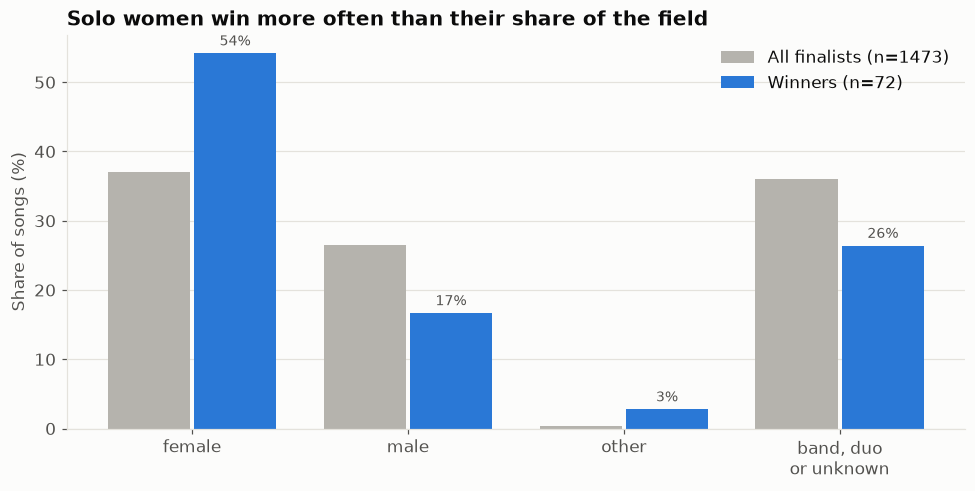

In [31]:
order = ["female", "male", "other", "band, duo or unknown"]
who = finals["artist_sex"].fillna("band, duo or unknown")
who_win = who[finals["winner"]]

fig, ax = plt.subplots(figsize=(9, 4.6))
compare(ax, shares(who, order), shares(who_win, order), len(who), len(who_win),
        labels=["female", "male", "other", "band, duo\nor unknown"])
ax.set_title("Solo women win more often than their share of the field")
plt.tight_layout(); plt.show()

## 4. Women among winners, decade by decade
Share of women among solo artists, for all finalists and for winners. A decade has about ten winners, so one winner moves the blue line by about ten points.

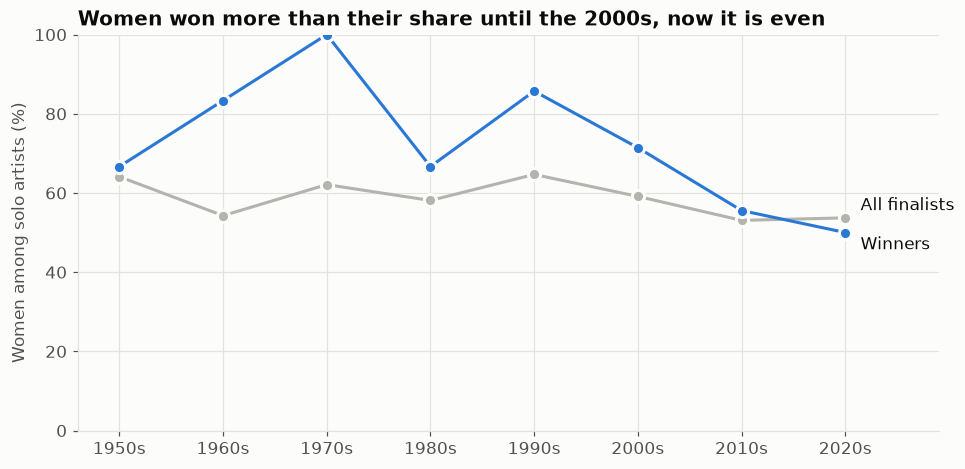

In [32]:
finals["decade"] = finals["year"] // 10 * 10
# share among solo artists, bands have no sex and are left out
female = finals["artist_sex"].dropna().eq("female")
by_decade = pd.DataFrame({
    "all": female.groupby(finals["decade"]).mean() * 100,
    "win": female[finals["winner"]].groupby(finals["decade"]).mean() * 100,
})

fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.arange(len(by_decade))
for column, color, label, dy in [("all", ALL, "All finalists", 8), ("win", WIN, "Winners", -8)]:
    ax.plot(x, by_decade[column], color=color, linewidth=2, marker="o", markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(label, (x[-1], by_decade[column].iloc[-1]), xytext=(10, dy),
                textcoords="offset points", va="center", color=INK)
ax.set_xticks(x, [f"{d}s" for d in by_decade.index])
ax.set_xlim(-0.4, len(x) - 0.1)
ax.set_ylim(0, 100)
ax.set_ylabel("Women among solo artists (%)")
ax.set_title("Women won more than their share until the 2000s, now it is even")
plt.tight_layout(); plt.show()

## 5. Running order
Where in the show the winner performed, 1956–2026, split into quarters of the running order. If the order did not matter, each quarter would hold 25% of the winners.

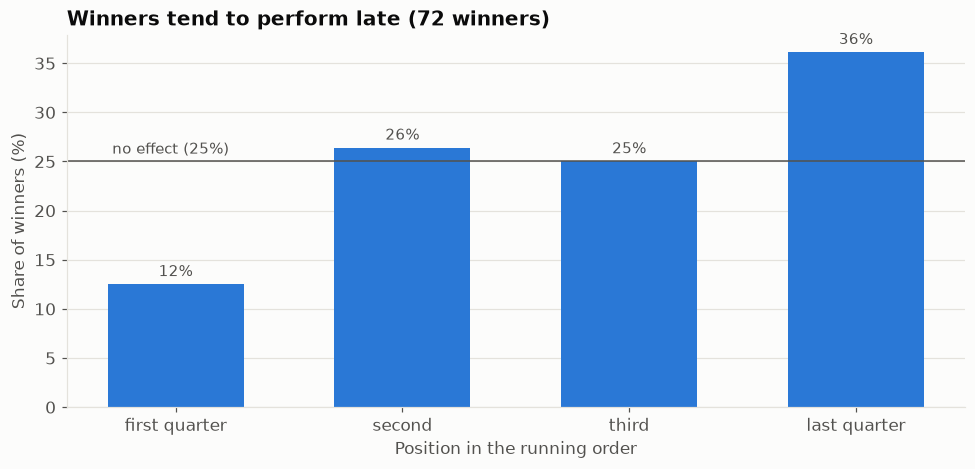

In [33]:
quarters = ["first quarter", "second", "third", "last quarter"]
finals["order_quarter"] = pd.cut(finals["order_share"], bins=[-0.01, 0.25, 0.5, 0.75, 1.0],
                                 labels=quarters)
order_win = finals.loc[finals["winner"], "order_quarter"]
win_share = shares(order_win, quarters) * 100

fig, ax = plt.subplots(figsize=(9, 4.4))
bars = ax.bar(quarters, win_share, color=WIN, width=0.6)
ax.bar_label(bars, fmt="%.0f%%", padding=3, color=INK2, fontsize=10)
ax.axhline(25, color=INK2, linewidth=1)
ax.text(-0.28, 25.8, "no effect (25%)", color=INK2, ha="left", fontsize=10)
ax.set_ylabel("Share of winners (%)")
ax.set_xlabel("Position in the running order")
ax.grid(axis="x", visible=False)
ax.set_title(f"Winners tend to perform late ({len(order_win)} winners)")
plt.tight_layout(); plt.show()

## 6. Song language
2008–2026, the years the lyrics analysis covers. **Missing: 2010** (no lyrics data, so the 2010 winner Lena is not here). English against everything else.

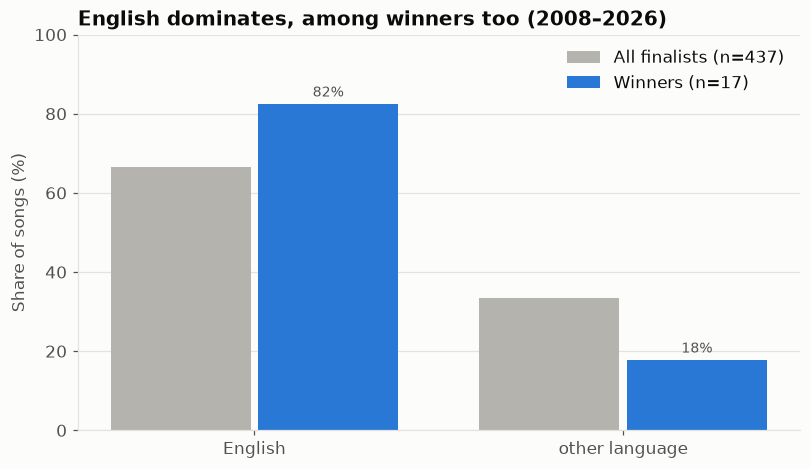

In [34]:
lang = finals.dropna(subset=["song_language"])
english = np.where(lang["song_language"] == "en", "English", "other language")
english = pd.Series(english, index=lang.index)
order = ["English", "other language"]

fig, ax = plt.subplots(figsize=(7.5, 4.4))
compare(ax, shares(english, order), shares(english[lang["winner"]], order),
        len(english), int(lang["winner"].sum()))
ax.set_ylim(0, 100)
ax.set_title(f"English dominates, among winners too ({lang['year'].min()}–{lang['year'].max()})")
plt.tight_layout(); plt.show()

## 7. What the lyrics are about
Mood and theme as read by an llm from the lyrics, 2008–2026. **Missing: 2010** (no lyrics data).

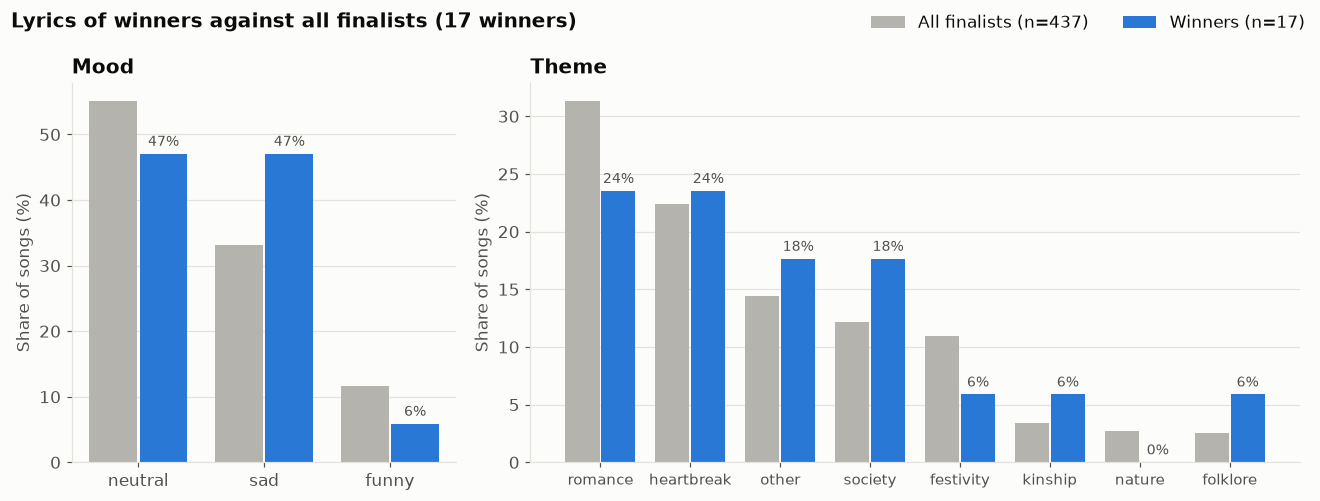

In [35]:
lyrics = pd.read_parquet(INTERIM / "lyric_features.parquet")
lyr = finals.merge(lyrics, on="entry_id", how="inner", validate="m:1")
lyr_win = lyr[lyr["winner"]]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 2]})
moods = ["neutral", "sad", "funny"]
compare(axes[0], shares(lyr["sentiment"], moods), shares(lyr_win["sentiment"], moods),
        len(lyr), len(lyr_win))
axes[0].set_title("Mood")
themes = lyr["theme"].value_counts().index.tolist()
compare(axes[1], shares(lyr["theme"], themes), shares(lyr_win["theme"], themes),
        len(lyr), len(lyr_win))
axes[1].set_title("Theme")
axes[1].tick_params(axis="x", labelsize=10)
axes[1].get_legend().remove()
handles, labels = axes[0].get_legend_handles_labels()
axes[0].get_legend().remove()
fig.legend(handles, labels, loc="upper right", ncol=2)
fig.suptitle(f"Lyrics of winners against all finalists ({len(lyr_win)} winners)", x=0.01,
             ha="left", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()

## 8. Google searches before the final
For each song: average search interest across all voting countries in the weeks before the final (web search on artist and song). Then every final's songs are ranked, 1 = searched most. This only uses data from before the final, so it can be used to predict.

2008–2026. **Missing: 2010** has no search data at all. In **2008 and 2009** most songs have 0 interest (too little search volume back then), so those songs share the last rank and the two years say little.

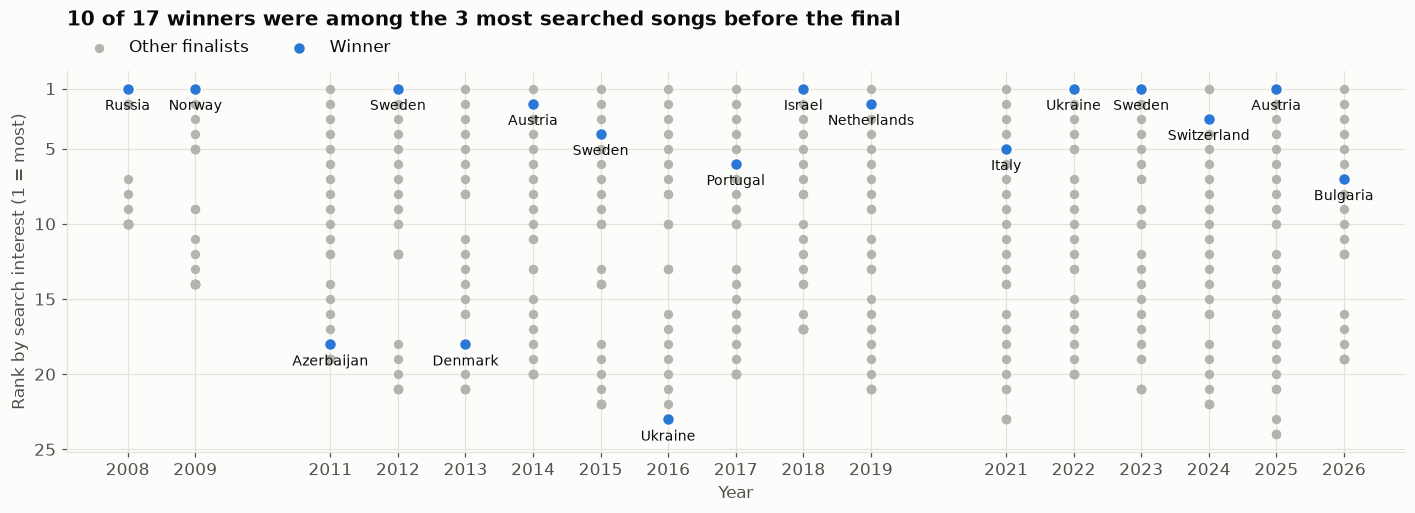

In [36]:
trends = pd.read_parquet(INTERIM / "trends.parquet")
interest = trends.groupby("entry_id")[["web_interest", "youtube_interest"]].mean()
ranked = finals.merge(interest, left_on="entry_id", right_index=True, how="inner")
ranked["search_rank"] = ranked.groupby("year")["web_interest"].rank(ascending=False, method="min")
top = ranked[ranked["winner"]].sort_values("year")

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.scatter(ranked["year"], ranked["search_rank"], s=26, color=ALL, label="Other finalists")
ax.scatter(top["year"], top["search_rank"], s=70, color=WIN, edgecolor=SURFACE,
           linewidth=1.5, zorder=3, label="Winner")
for _, row in top.iterrows():
    ax.annotate(name.get(row["country_iso3"], row["country_iso3"]),
                (row["year"], row["search_rank"]), xytext=(0, -14),
                textcoords="offset points", ha="center", fontsize=9, color=INK)
ax.invert_yaxis()
ax.set_yticks([1, 5, 10, 15, 20, 25])
ax.set_ylabel("Rank by search interest (1 = most)")
ax.set_xlabel("Year")
ax.set_xticks(sorted(ranked["year"].unique()))
in_top3 = int((top["search_rank"] <= 3).sum())
ax.set_title(f"{in_top3} of {len(top)} winners were among the 3 most searched songs before the final", pad=30)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
plt.tight_layout(); plt.show()

## 9. Countries with the most wins
1956–2026. The grey bar is how many finals the country took part in.

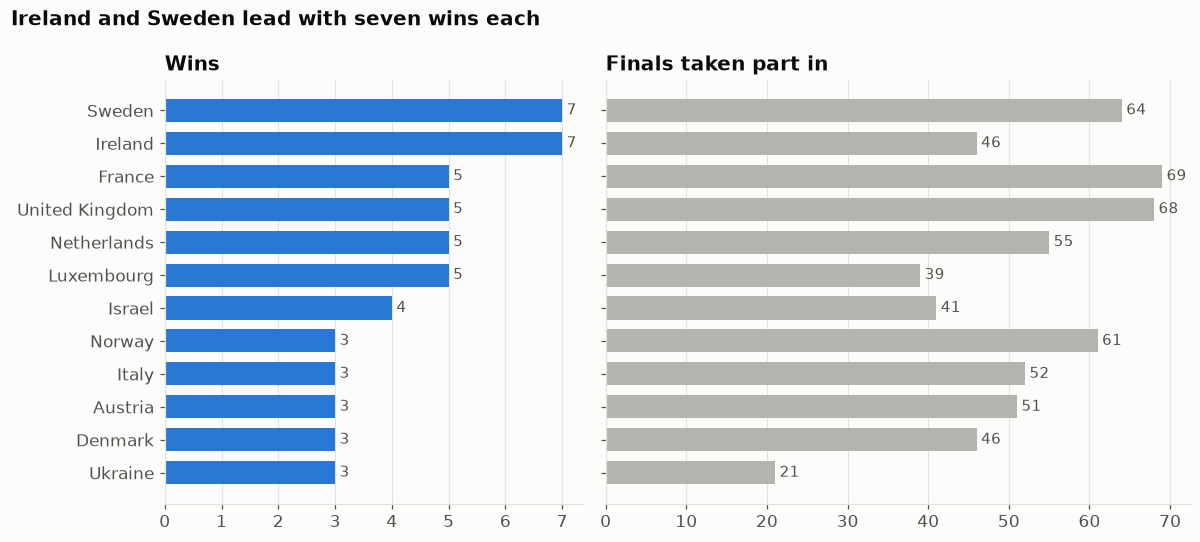

In [37]:
per_country = finals.groupby("country_iso3").agg(finals=("entry_id", "size"), wins=("winner", "sum"))
per_country = per_country[per_country["wins"] > 0].sort_values(["wins", "finals"]).tail(12)
labels = [name.get(c, c) for c in per_country.index]

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True, gridspec_kw={"width_ratios": [1, 1.4]})
bars = axes[0].barh(labels, per_country["wins"], color=WIN, height=0.7)
axes[0].bar_label(bars, padding=3, color=INK2, fontsize=10)
axes[0].set_title("Wins")
axes[0].grid(axis="y", visible=False)
bars = axes[1].barh(labels, per_country["finals"], color=ALL, height=0.7)
axes[1].bar_label(bars, padding=3, color=INK2, fontsize=10)
axes[1].set_title("Finals taken part in")
axes[1].grid(axis="y", visible=False)
fig.suptitle("Ireland and Sweden lead with seven wins each", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()